In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import time
import os
from tempfile import TemporaryDirectory
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Define transformations for training and validation
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize(256),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Download and load the Oxford-IIIT Pet dataset
train_data = datasets.OxfordIIITPet(root='./data', split='trainval', transform=data_transforms['train'], download=True)
test_data = datasets.OxfordIIITPet(root='./data', split='test', transform=data_transforms['val'], download=True)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=16, shuffle=False, num_workers=0)

class_names = train_data.classes
print(f"Loaded {len(class_names)} pet classes.")

100%|██████████| 792M/792M [00:20<00:00, 38.9MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 19.3MB/s]


Loaded 37 pet classes.


In [ ]:
# Load pre-trained MobileNetV2
net = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze the base parameters for Phase 1
for param in net.parameters():
    param.requires_grad = False

# MobileNetV2's classifier is a Sequential block. The linear layer is at index 1.
# We replace it with a new Linear layer matching our 37 pet classes.
num_features = net.classifier[1].in_features
net.classifier[1] = nn.Linear(num_features, len(class_names))

net = net.to(device)

# Define loss function and optimizer (only optimizing the new classifier head)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.classifier.parameters(), lr=0.001)

# New Scheduler: Reduce LR if the validation loss stops improving for 2 epochs
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

dataloaders = {'train': train_loader, 'val': test_loader}
dataset_sizes = {'train': len(train_data), 'val': len(test_data)}

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 112MB/s] 


In [ ]:
from tqdm.auto import tqdm
import time
import os
from tempfile import TemporaryDirectory

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

num_epochs = 5 # PHASE 1: Only train the head for 5 epochs
since = time.time()
best_acc = 0.0

tempdir = TemporaryDirectory()
best_model_params_path = os.path.join(tempdir.name, 'best_model_params.pt')
torch.save(net.state_dict(), best_model_params_path)

for epoch in range(num_epochs):
    print(f'Phase 1 | Epoch {epoch+1}/{num_epochs}')
    print('-' * 10)

    for phase in ['train', 'val']:
        if phase == 'train':
            net.train()
        else:
            net.eval()

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in tqdm(dataloaders[phase], desc=f'{phase} Epoch {epoch+1}'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = net(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = (running_corrects / dataset_sizes[phase]) * 100

        print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.2f}%')

        if phase == 'train':
            train_losses.append(epoch_loss)
            train_accuracies.append(epoch_acc)
        else:
            val_losses.append(epoch_loss)
            val_accuracies.append(epoch_acc)
            # Step the plateau scheduler using validation loss!
            scheduler.step(epoch_loss)

            if epoch_acc > best_acc:
                best_acc = epoch_acc
                torch.save(net.state_dict(), best_model_params_path)
    print()

# Load Phase 1 best weights
net.load_state_dict(torch.load(best_model_params_path, weights_only=True))
print("Phase 1 complete! Classifier head is stabilized.")

Phase 1 | Epoch 1/5
----------


train Epoch 1:   0%|          | 0/230 [00:00<?, ?it/s]

train Loss: 2.3351 Acc: 47.31%


val Epoch 1:   0%|          | 0/230 [00:00<?, ?it/s]

val Loss: 1.2005 Acc: 74.65%

Phase 1 | Epoch 2/5
----------


train Epoch 2:   0%|          | 0/230 [00:00<?, ?it/s]

... (11 outputs left out)

train Epoch 5:   0%|          | 0/230 [00:00<?, ?it/s]

train Loss: 0.9783 Acc: 72.85%


val Epoch 5:   0%|          | 0/230 [00:00<?, ?it/s]

val Loss: 0.5509 Acc: 84.27%

Phase 1 complete! Classifier head is stabilized.


In [ ]:
print("--- STARTING PHASE 2: FULL FINE-TUNING ---")

# 1. Unfreeze all layers in the network
for param in net.parameters():
    param.requires_grad = True

# 2. Create a NEW optimizer with a VERY low learning rate (e.g., 1e-4)
# We don't want to make huge adjustments and destroy the pre-trained weights
optimizer_ft = optim.Adam(net.parameters(), lr=1e-4)

# 3. New scheduler for Phase 2
scheduler_ft = lr_scheduler.ReduceLROnPlateau(optimizer_ft, mode='min', factor=0.1, patience=2)

num_epochs_ft = 10 # Train the whole network for 10 more epochs

for epoch in range(num_epochs_ft):
    print(f'Phase 2 | Epoch {epoch+1}/{num_epochs_ft}')
    print('-' * 10)

    for phase in ['train', 'val']:
        if phase == 'train':
            net.train()
        else:
            net.eval()

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in tqdm(dataloaders[phase], desc=f'FT {phase} Epoch {epoch+1}'):
            inputs = inputs.to(device)
            labels = labels.to(device)
            optimizer_ft.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = net(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer_ft.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = (running_corrects / dataset_sizes[phase]) * 100
        print(f'FT {phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.2f}%')

        if phase == 'train':
            train_losses.append(epoch_loss)
            train_accuracies.append(epoch_acc)
        else:
            val_losses.append(epoch_loss)
            val_accuracies.append(epoch_acc)
            scheduler_ft.step(epoch_loss)

            if epoch_acc > best_acc:
                best_acc = epoch_acc
                torch.save(net.state_dict(), best_model_params_path)
    print()

time_elapsed = time.time() - since
print(f'Total Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Absolute Best Val Acc: {best_acc:4f}%')

# Load the absolute best weights back into the model
net.load_state_dict(torch.load(best_model_params_path, weights_only=True))
tempdir.cleanup()

--- STARTING PHASE 2: FULL FINE-TUNING ---
Phase 2 | Epoch 1/10
----------


FT train Epoch 1:   0%|          | 0/230 [00:00<?, ?it/s]

FT train Loss: 0.8044 Acc: 76.66%


FT val Epoch 1:   0%|          | 0/230 [00:00<?, ?it/s]

FT val Loss: 0.4193 Acc: 87.03%

Phase 2 | Epoch 2/10
----------


FT train Epoch 2:   0%|          | 0/230 [00:00<?, ?it/s]

... (31 outputs left out)

FT train Epoch 10:   0%|          | 0/230 [00:00<?, ?it/s]

FT train Loss: 0.4104 Acc: 88.02%


FT val Epoch 10:   0%|          | 0/230 [00:00<?, ?it/s]

FT val Loss: 0.3496 Acc: 88.88%

Total Training complete in 16m 2s
Absolute Best Val Acc: 89.261379%


In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 89 %


In [ ]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in class_names}
total_pred = {classname: 0 for classname in class_names}

with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[class_names[label]] += 1
            total_pred[class_names[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: Abyssinian is 91.8 %
Accuracy for class: American Bulldog is 87.0 %
Accuracy for class: American Pit Bull Terrier is 54.0 %
Accuracy for class: Basset Hound is 89.0 %
Accuracy for class: Beagle is 90.0 %
Accuracy for class: Bengal is 84.0 %
Accuracy for class: Birman is 89.0 %
Accuracy for class: Bombay is 92.0 %
Accuracy for class: Boxer is 87.9 %
Accuracy for class: British Shorthair is 82.0 %
Accuracy for class: Chihuahua is 88.0 %
Accuracy for class: Egyptian Mau is 87.6 %
Accuracy for class: English Cocker Spaniel is 94.0 %
Accuracy for class: English Setter is 88.0 %
Accuracy for class: German Shorthaired is 99.0 %
Accuracy for class: Great Pyrenees is 97.0 %
Accuracy for class: Havanese is 98.0 %
Accuracy for class: Japanese Chin is 100.0 %
Accuracy for class: Keeshond is 98.0 %
Accuracy for class: Leonberger is 98.0 %
Accuracy for class: Maine Coon is 85.0 %
Accuracy for class: Miniature Pinscher is 85.0 %
Accuracy for class: Newfoundland is 93.0 %
Accuracy 

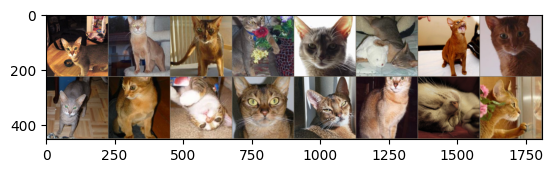

GroundTruth:  Abyssinian Abyssinian Abyssinian Abyssinian
Predicted:    Abyssinian Abyssinian Abyssinian Abyssinian


In [ ]:
import torchvision
import matplotlib.pyplot as plt
import numpy as np

# Helper function to un-normalize and display an image
def imshow(img):
    # Reversing ImageNet normalization: img * std + mean
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    img = img.numpy() * std + mean
    img = np.clip(img, 0, 1)
    plt.imshow(np.transpose(img, (1, 2, 0)))
    plt.show()

# Get a single batch of test data
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Display the images
imshow(torchvision.utils.make_grid(images.cpu()))

# Print the true labels
print('GroundTruth: ', ' '.join(f'{class_names[labels[j]]:5s}' for j in range(4)))

# Move the images to the GPU BEFORE passing to the network
images = images.to(device)

# Get predictions
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{class_names[predicted[j]]:5s}' for j in range(4)))

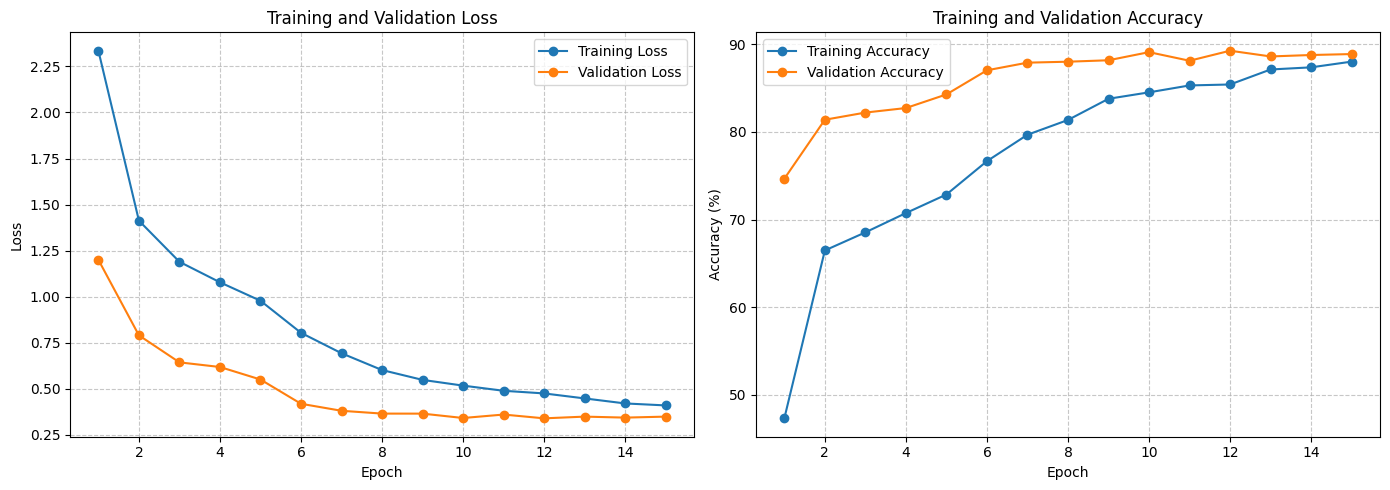

In [ ]:
import matplotlib.pyplot as plt

# Dynamically size epochs based on the actual number of metrics collected
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(14, 5))

# Plot Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Plot Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(epochs, val_accuracies, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

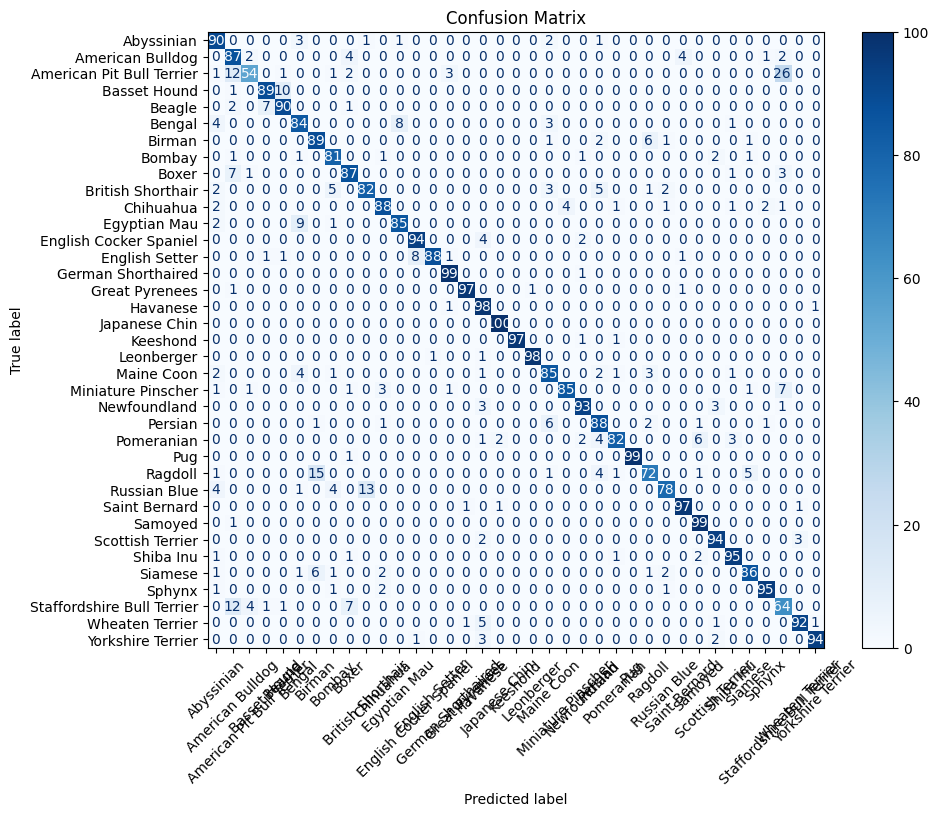

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Collect all true labels and model predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate and plot the confusion matrix using Scikit-Learn's native display
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))

# Configure and draw the plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')

plt.title('Confusion Matrix')
plt.show()

In [ ]:
import time
import os
import torch
from torch.utils.mobile_optimizer import optimize_for_mobile

print("--- Efficiency and Speed Metrics ---")

# Ensure the model is in evaluation mode and on CPU for mobile simulation
net.eval()
net.cpu()

# Create a dummy input mimicking one smartphone photo
dummy_input = torch.rand(1, 3, 224, 224)

# Trace the model and optimize for mobile
scripted_module = torch.jit.trace(net, dummy_input)
optimized_scripted_module = optimize_for_mobile(scripted_module)

# Save the mobile optimized model
model_filename = "pet_breed_mobilenet_v2_mobile.ptl"
optimized_scripted_module._save_for_lite_interpreter(model_filename)

# 1. Measure the physical file size of the mobile model
file_size_mb = os.path.getsize(model_filename) / (1024 * 1024)
print(f"Mobile Model File Size: {file_size_mb:.2f} MB")

# 2. Count total trainable parameters
total_params = sum(p.numel() for p in net.parameters())
print(f"Total Parameters: {total_params:,}")

# 3. CPU Inference Latency Test (Simulating a smartphone)
# Warm-up runs (to initialize the CPU cache and prevent slow first-runs)
with torch.no_grad():
    for _ in range(10):
        _ = optimized_scripted_module(dummy_input)

# Benchmark 100 forward passes
num_iterations = 100
start_time = time.time()

with torch.no_grad():
    for _ in range(num_iterations):
        _ = optimized_scripted_module(dummy_input)

end_time = time.time()

# Calculate average latency and throughput
total_time = end_time - start_time
avg_latency_ms = (total_time / num_iterations) * 1000
fps = 1000 / avg_latency_ms

print(f"\nAverage CPU Inference Latency: {avg_latency_ms:.2f} ms per image")
print(f"Throughput: {fps:.2f} Frames Per Second (FPS)")

# Restore model to original device (GPU if available)
net.to(device)

--- Efficiency and Speed Metrics ---


/tmp/ipykernel_455/3402244968.py:21: DeprecationWarning: Lite Interpreter is deprecated. Please consider switching to ExecuTorch.             https://docs.pytorch.org/executorch/stable/getting-started.html
  optimized_scripted_module._save_for_lite_interpreter(model_filename)


Mobile Model File Size: 8.57 MB
Total Parameters: 2,271,269

Average CPU Inference Latency: 32.96 ms per image
Throughput: 30.34 Frames Per Second (FPS)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=